# hiNiche on single-cell spatial data (single slice): mouse V1 STARmap

> **Environment:** run this notebook in the main **`hiNiche`** environment (`environment.yml`).

This notebook applies hiNiche (`hiNiche_img`, cell → niche) to a single STARmap slice of the mouse visual cortex (V1). The cell / niche embeddings are written to the AnnData, and niche clusters are evaluated against the annotated cortical layers (`adata.obs[LABEL_KEY]`).

## 1. Imports

In [4]:
import config
import utils
import model
from train import run_train_img

import anndata as ad
import scanpy as sc
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import os
import glob
import warnings
import json
from tqdm import tqdm

from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
from sklearn.cluster import KMeans

%load_ext autoreload
%autoreload 2

warnings.filterwarnings("ignore")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Configuration

Data paths, the ground-truth columns (`LABEL_KEY`, `CELLTYPE_KEY`), the patch directory (`PATCH_LOC`) and model / training hyperparameters.

In [5]:
SAMPLE = "Mouse_brain_STARmap_single_slice"

# Data paths: a single-slice AnnData (raw counts in adata.X)
h5_path      = f"DATA/{SAMPLE}/STARmap.h5ad"
LABEL_KEY    = "Layer"         # ground-truth cortical layer (used for evaluation)
CELLTYPE_KEY = "Cell_type"     # cell-type annotation (used for visualization)

# Patch save path
PATCH_LOC = f"DATA/{SAMPLE}/mini_batch_cache"

# Model save path (if the file exists, the model is loaded and training is skipped)
MODEL_SAVE_DIR = f"DATA/{SAMPLE}/checkpoint.pt"

# Model / training hyperparameters
single_patch = True    # the whole slice is used as a single patch
n_pcs       = 30
graph_knn   = 12
niche_knn   = 20
hidden_dim  = 32
lr          = 0.005
num_epochs  = 100
edge_drop   = 0.5
member_drop = 0.5
neg_samples = 5
tau         = 1
seed        = 42
n_clusters  = 7        # number of annotated layers in LABEL_KEY
device      = "cuda:0"

## 3. Load data

Read the AnnData and show the annotated cell types and cortical layers.

AnnData object with n_obs × n_vars = 1207 × 1020
    obs: 'Cell', 'Cell_type', 'X', 'Y', 'Layer'
    obsm: 'spatial'


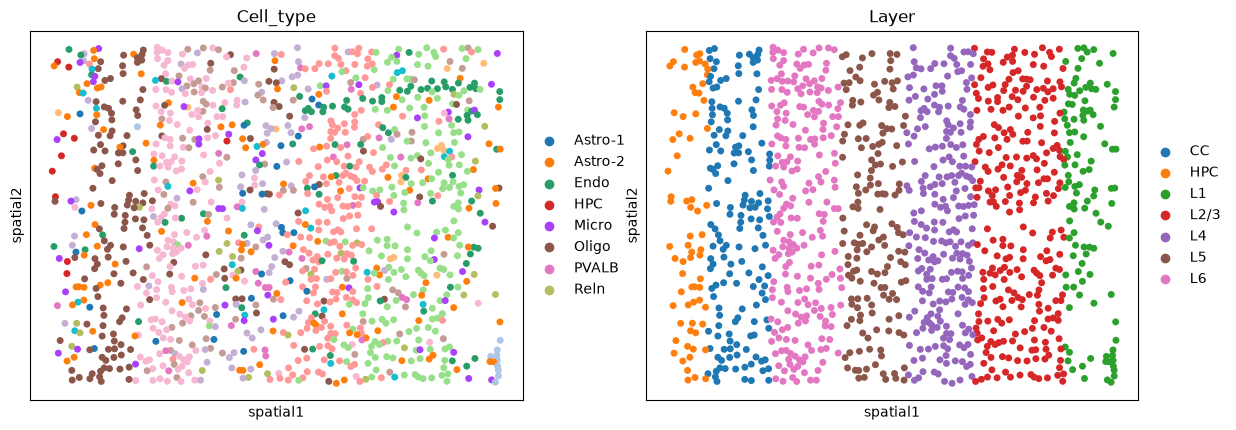

In [6]:
adata = sc.read(h5_path)
adata.var_names_make_unique()
print(adata)

sc.pl.embedding(adata, basis="spatial", color=[CELLTYPE_KEY, LABEL_KEY], s=100)

## 4. Build graphs, niches and mini-batch

Normalize + log1p the raw counts, scale + PCA, build KNN niches (`niche_knn` cells per niche), the cell graph (expression PCA KNN) and the niche graph (spatial KNN), then cache the slice as a single block in `PATCH_LOC`.

In [7]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

X_backup = adata.X.copy()
sc.pp.scale(adata)
sc.tl.pca(adata, n_comps=n_pcs)
adata.X = X_backup

adata.obsm["X_input"] = adata.X
adata.obsm["X_mle"] = adata.layers["counts"]
spatial_coords_px = adata.obsm["spatial"]

# Each niche = a center cell and its niche_knn nearest cells (including itself)
S_c2n_all, _, _ = utils.build_cell_niche_mapping_knn(spatial_coords_px, k_niche = niche_knn)

cell_edges = utils.build_spot_knn_graph(adata.obsm["X_pca"], graph_knn)    # cell graph: expression (PCA) KNN
niche_edges = utils.build_spot_knn_graph(spatial_coords_px, graph_knn)     # niche graph: spatial KNN
batch_mask, block_ids = utils.make_cell_block_masks(spatial_coords_px, S_c2n = S_c2n_all, single_patch = single_patch)

# Remove old blocks, otherwise the loader would also read leftovers from a previous run
for f in glob.glob(os.path.join(PATCH_LOC, "block_*.pt")):
    os.remove(f)
utils.build_cell_subgraph_data(adata, ref_matrix = None,
                               cell_edges = cell_edges,
                               niche_edges = niche_edges,
                               S_c2n_all = S_c2n_all,
                               batch_mask = batch_mask,
                               block_ids = block_ids,
                               save_dir = PATCH_LOC)

sample_number = {"cell": S_c2n_all.shape[0], "niche": S_c2n_all.shape[1]}

[Log] Active niches: 1207, Cells per niche (k): 20
[Log] 22754 edges generated from 1207 nodes (k=12)
[Log] 16398 edges generated from 1207 nodes (k=12)


[Log] Building & saving cell mini-batches: 100%|██████████| 1/1 [00:00<00:00,  7.61it/s]

[Log] saved 1 cell blocks → DATA/Mouse_brain_STARmap_single_slice/mini_batch_cache


## 5. Training

Single slice: pass a dict of unit numbers and a single patch directory. If `MODEL_SAVE_DIR` already exists, the model is loaded and training is skipped. Embeddings are written to `adata.obsm["X_cell_emb"]` and `adata.obsm["X_niche_emb"]`.

In [8]:
emb_all, _ = run_train_img(sample_number,
                           PATCH_LOC = PATCH_LOC,
                           MODEL_SAVE_DIR = MODEL_SAVE_DIR,
                           ref_matrix = None,
                           lr = lr,
                           in_dim = adata.n_vars,
                           hidden_dim = hidden_dim,
                           num_epochs = num_epochs,
                           edge_drop = edge_drop,
                           member_drop = member_drop,
                           neg_samples = neg_samples,
                           tau = tau,
                           seed = seed,
                           device = device)

# With KNN niches every cell is a niche center, so niche embeddings are aligned with cells as well
adata.obsm["X_cell_emb"]  = emb_all["cell"].detach().cpu().numpy()
adata.obsm["X_niche_emb"] = emb_all["niche"].detach().cpu().numpy()

Epoch 100: 100%|██████████| 1/1 [00:00<00:00, 43.82it/s, cl=2.8283]


Training finished!
Model saved to DATA/Mouse_brain_STARmap_single_slice/checkpoint.pt


generating embeddings (slice 0)...: 100%|██████████| 1/1 [00:00<00:00, 40.42it/s]


## 6. Clustering and visualization

KMeans on the cell and niche embeddings, plotted next to the annotated cell types (`CELLTYPE_KEY`) and cortical layers (`LABEL_KEY`). Labels are stored in `adata.obs["kmeans_cell"]` / `adata.obs["kmeans_niche"]`.

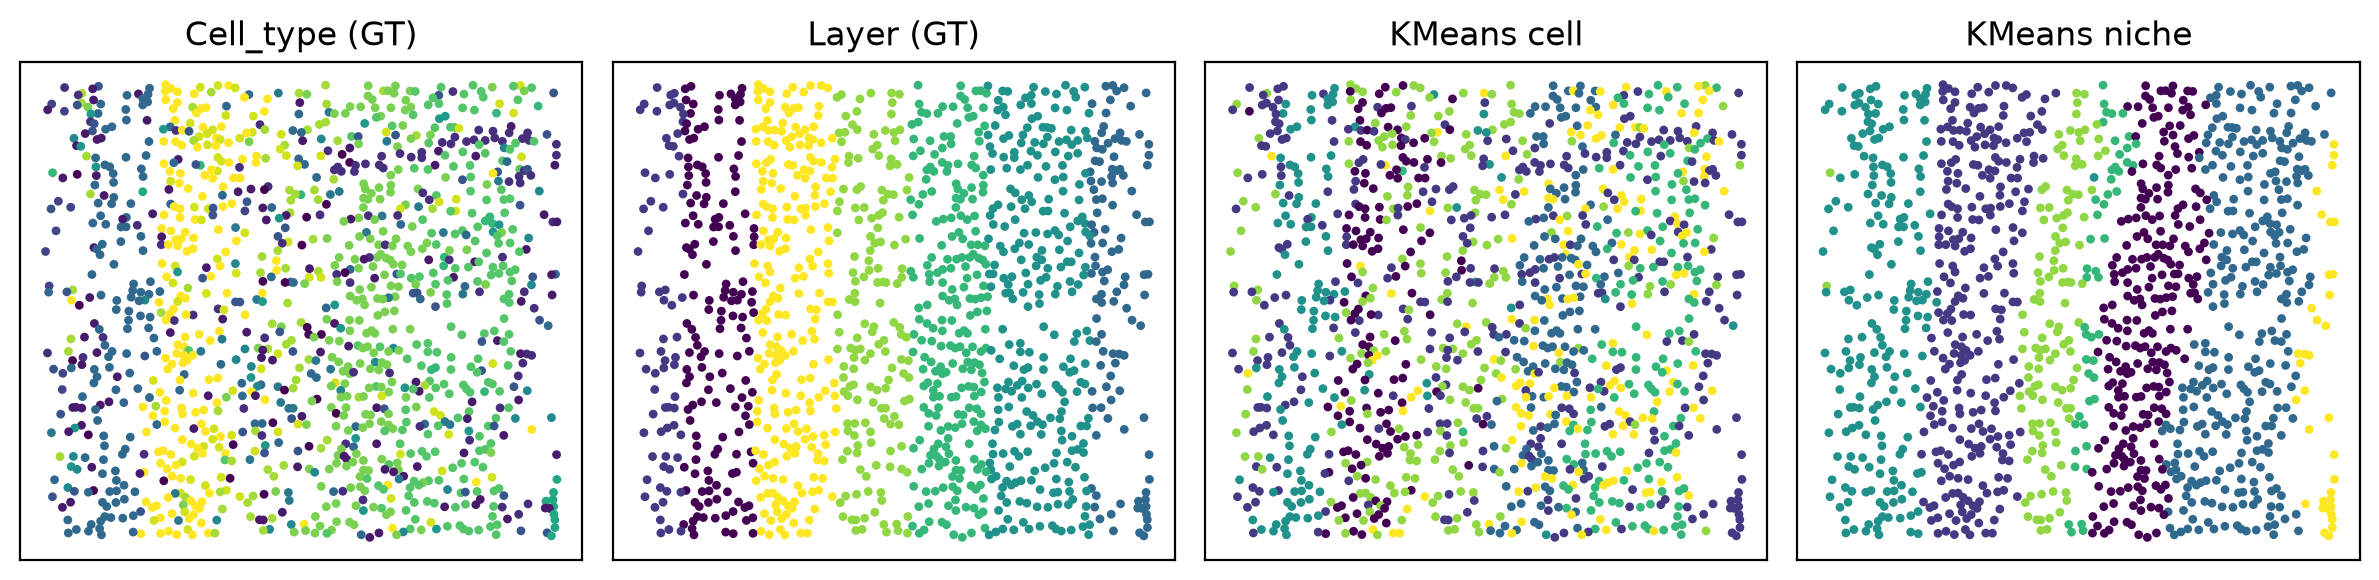

In [9]:
spatial = adata.obsm["spatial"]
x, y = spatial[:, 0], spatial[:, 1]

X_cell  = np.asarray(adata.obsm["X_cell_emb"])
X_niche = np.asarray(adata.obsm["X_niche_emb"])

labels_cell  = KMeans(n_clusters=n_clusters, random_state=42, n_init=20).fit_predict(X_cell)
labels_niche = KMeans(n_clusters=n_clusters, random_state=42, n_init=20).fit_predict(X_niche)

adata.obs["kmeans_cell"]  = pd.Categorical(labels_cell.astype(str))
adata.obs["kmeans_niche"] = pd.Categorical(labels_niche.astype(str))

# Ground-truth labels
point_size = 10
celltype = adata.obs[CELLTYPE_KEY].astype("category")
layer = adata.obs[LABEL_KEY].astype("category")

fig, axes = plt.subplots(1, 4, figsize=(12, 3), dpi=200)
panels = [(celltype.cat.codes, f"{CELLTYPE_KEY} (GT)"),
          (layer.cat.codes,    f"{LABEL_KEY} (GT)"),
          (labels_cell,        "KMeans cell"),
          (labels_niche,       "KMeans niche")]
for ax, (c, title) in zip(axes, panels):
    ax.scatter(x, y, c=c, s=point_size, linewidths=0)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 7. Evaluation (NMI / ARI)

Agreement of the cell and niche clusters with the annotated cortical layers (`LABEL_KEY`).

In [10]:
true_labels = adata.obs[LABEL_KEY]

nmi_cell  = normalized_mutual_info_score(true_labels, labels_cell)
ari_cell  = adjusted_rand_score(true_labels, labels_cell)
nmi_niche = normalized_mutual_info_score(true_labels, labels_niche)
ari_niche = adjusted_rand_score(true_labels, labels_niche)

print(f"Cell:  NMI: {nmi_cell:.4f}, ARI: {ari_cell:.4f}")
print(f"Niche: NMI: {nmi_niche:.4f}, ARI: {ari_niche:.4f}")

Cell:  NMI: 0.3164, ARI: 0.1875
Niche: NMI: 0.7189, ARI: 0.6296
